In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gamma as gamma_dist
from scipy.optimize import minimize
import h5py
from pathlib import Path

In [39]:
base_dir      = Path("/Users/angelaliu/Library/CloudStorage/OneDrive-MassachusettsInstituteofTechnology/Fracture Flow UROP")
transport_dir = base_dir / "Updated Code" / "transport narrowed param ranges"
outputs_dir   = base_dir / "outputs"
outputs_dir.mkdir(exist_ok=True)
mat_path = transport_dir / "all_trial_bkt_data.mat"

In [40]:
# Fixed x-axis range for all BKT plots — adjust after first visual inspection
X_MIN = 1e2   # seconds
X_MAX = 1e8   # seconds
Y_MIN = 1e-3 # resolution floor: 1/1000 particles per trial


In [41]:
def load_all_trial_bkt_data(mat_path):
    """
    Load all_trial_bkt_data from a MATLAB v7.3 (.mat / HDF5) file.
    Returns:
      param_sets : list of dicts {'p0': float, 'trial_data': list of np.ndarray}
                   p0 = probability of zero flow (disconnected trial)
                   each trial array is empty (len 0) for disconnected trials
      weights    : (num_param_sets, 3) array — same random draws used in MATLAB
    """
    param_sets = []
    with h5py.File(mat_path, 'r') as f:
        # weights: MATLAB (N,3) -> HDF5 (3,N); transpose back
        weights = f['weights'][()].T  # (num_param_sets, 3)

        atbd = f['all_trial_bkt_data']  # (1, 100) object refs

        for i in range(atbd.shape[1]):
            ps_grp = f[atbd[0, i]]

            p0 = float(ps_grp['p0'][()].flat[0])

            td = ps_grp['trial_data']  # (1, 1000) object refs
            trial_data = []
            for j in range(td.shape[1]):
                arr = f[td[0, j]][()]
                # connected trial -> float64 (1, 1000); disconnected -> uint64 [0,0]
                if arr.dtype == np.float64:
                    trial_data.append(arr.flatten())
                else:
                    trial_data.append(np.array([], dtype=np.float64))

            param_sets.append({'p0': p0, 'trial_data': trial_data})

    return param_sets, weights


param_sets, weights = load_all_trial_bkt_data(mat_path)
print(f"Loaded {len(param_sets)} param sets, "
      f"{len(param_sets[0]['trial_data'])} trials each")

Loaded 100 param sets, 1000 trials each


In [42]:
def fit_gamma_mixture(bkt_samples, n_init=5, seed=0):
    """
    Fit a 2-component gamma mixture to breakthrough time samples via MLE.
    Mixture PDF: w1*Gamma(t;a1,s1) + (1-w1)*Gamma(t;a2,s2)
    where s = scale = 1/rate.
    Components are ordered by mean (a*s) ascending.
    Returns dict with w1, alpha1, beta1, alpha2, beta2, nll, or None if too few samples.
    """
    t = np.asarray(bkt_samples, dtype=float)
    t = t[np.isfinite(t) & (t > 0)]
    if len(t) < 5:
        return None

    rng = np.random.default_rng(seed)

    def neg_log_lik(params):
        w1_raw, la1, ls1, la2, ls2 = params
        w1 = 1.0 / (1.0 + np.exp(-np.clip(w1_raw, -20, 20)))
        a1, s1 = np.exp(np.clip(la1, -10, 15)), np.exp(np.clip(ls1, -10, 30))
        a2, s2 = np.exp(np.clip(la2, -10, 15)), np.exp(np.clip(ls2, -10, 30))
        pdf = w1 * gamma_dist.pdf(t, a=a1, scale=s1) + (1.0 - w1) * gamma_dist.pdf(t, a=a2, scale=s2)
        return -np.sum(np.log(np.clip(pdf, 1e-300, None)))

    def mom(x):
        m, v = np.mean(x), np.var(x)
        if v < 1e-30:
            v = m ** 2 * 0.1
        return max(m ** 2 / v, 0.1), max(v / m, 1e-10)

    best_res, best_nll = None, np.inf
    for _ in range(n_init):
        q = rng.uniform(0.15, 0.85)
        split = np.quantile(t, q)
        t_lo = t[t <= split] if np.any(t <= split) else t
        t_hi = t[t >  split] if np.any(t >  split) else t
        a1_0, s1_0 = mom(t_lo)
        a2_0, s2_0 = mom(t_hi)
        w0 = np.clip(len(t_lo) / len(t), 1e-4, 1 - 1e-4)
        x0 = [np.log(w0 / (1 - w0)), np.log(a1_0), np.log(s1_0),
               np.log(a2_0), np.log(s2_0)]
        try:
            res = minimize(neg_log_lik, x0, method='Nelder-Mead',
                           options={'maxiter': 5000, 'xatol': 1e-6, 'fatol': 1e-6,
                                    'adaptive': True})
            if res.fun < best_nll:
                best_res, best_nll = res, res.fun
        except Exception:
            continue

    if best_res is None:
        return None

    w1_raw, la1, ls1, la2, ls2 = best_res.x
    w1 = 1.0 / (1.0 + np.exp(-np.clip(w1_raw, -20, 20)))
    a1, s1 = np.exp(np.clip(la1, -10, 15)), np.exp(np.clip(ls1, -10, 30))
    a2, s2 = np.exp(np.clip(la2, -10, 15)), np.exp(np.clip(ls2, -10, 30))

    if a1 * s1 > a2 * s2:
        w1, a1, s1, a2, s2 = 1.0 - w1, a2, s2, a1, s1

    return {'w1': float(w1), 'alpha1': float(a1), 'beta1': float(s1),
            'alpha2': float(a2), 'beta2': float(s2), 'nll': float(best_nll)}

In [43]:
def fit_gamma_mixture_loglog(bkt_samples, n_init=5, seed=0):
    """
    Fit a 2-component gamma mixture by minimising SSE in log(CCDF) vs log(t).
    Weights the tail more uniformly than MLE.
    Returns dict with w1, alpha1, beta1, alpha2, beta2, sse, or None if <5 samples.
    """
    t = np.asarray(bkt_samples, dtype=float)
    t = np.sort(t[np.isfinite(t) & (t > 0)])
    if len(t) < 5:
        return None

    n = len(t)
    # Weibull plotting positions — always in (0, 1), so log is defined
    S_emp     = (n - np.arange(n)) / (n + 1)
    log_S_emp = np.log(S_emp)

    rng = np.random.default_rng(seed)

    def objective(params):
        w1_raw, la1, ls1, la2, ls2 = params
        w1 = 1.0 / (1.0 + np.exp(-np.clip(w1_raw, -20, 20)))
        a1, s1 = np.exp(np.clip(la1, -10, 15)), np.exp(np.clip(ls1, -10, 30))
        a2, s2 = np.exp(np.clip(la2, -10, 15)), np.exp(np.clip(ls2, -10, 30))
        S_fit = (w1 * (1 - gamma_dist.cdf(t, a=a1, scale=s1)) +
                 (1 - w1) * (1 - gamma_dist.cdf(t, a=a2, scale=s2)))
        return np.sum((log_S_emp - np.log(np.clip(S_fit, 1e-300, None))) ** 2)

    def mom(x):
        m, v = np.mean(x), np.var(x)
        if v < 1e-30:
            v = m ** 2 * 0.1
        return max(m ** 2 / v, 0.1), max(v / m, 1e-10)

    best_res, best_obj = None, np.inf
    for _ in range(n_init):
        q = rng.uniform(0.15, 0.85)
        split = np.quantile(t, q)
        t_lo = t[t <= split] if np.any(t <= split) else t
        t_hi = t[t >  split] if np.any(t >  split) else t
        a1_0, s1_0 = mom(t_lo)
        a2_0, s2_0 = mom(t_hi)
        w0 = np.clip(len(t_lo) / len(t), 1e-4, 1 - 1e-4)
        x0 = [np.log(w0 / (1 - w0)), np.log(a1_0), np.log(s1_0),
               np.log(a2_0), np.log(s2_0)]
        try:
            res = minimize(objective, x0, method='Nelder-Mead',
                           options={'maxiter': 5000, 'xatol': 1e-6, 'fatol': 1e-6,
                                    'adaptive': True})
            if res.fun < best_obj:
                best_res, best_obj = res, res.fun
        except Exception:
            continue

    if best_res is None:
        return None

    w1_raw, la1, ls1, la2, ls2 = best_res.x
    w1 = 1.0 / (1.0 + np.exp(-np.clip(w1_raw, -20, 20)))
    a1, s1 = np.exp(np.clip(la1, -10, 15)), np.exp(np.clip(ls1, -10, 30))
    a2, s2 = np.exp(np.clip(la2, -10, 15)), np.exp(np.clip(ls2, -10, 30))

    if a1 * s1 > a2 * s2:
        w1, a1, s1, a2, s2 = 1.0 - w1, a2, s2, a1, s1

    return {'w1': float(w1), 'alpha1': float(a1), 'beta1': float(s1),
            'alpha2': float(a2), 'beta2': float(s2), 'sse': float(best_obj)}

Param set 2, trial 2: 1000 breakthrough times
MLE fit time: 0.8s  |  NLL=11750.43
Log-log fit time: 1.4s  |  SSE=18.0752


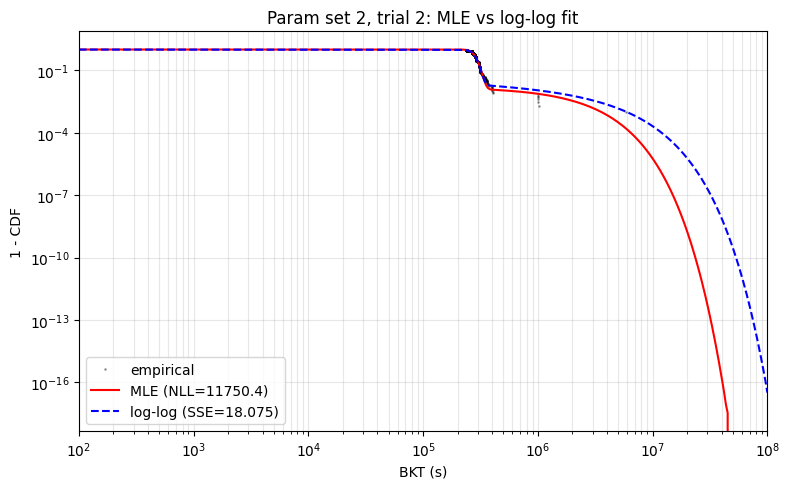

In [44]:
# Test: compare MLE fit vs log-log fit on a single trial
import time

test_ps_idx = next(i for i, ps in enumerate(param_sets) if ps['p0'] < 1.0)
ps = param_sets[test_ps_idx]
j, bkt = next((j, bkt) for j, bkt in enumerate(ps['trial_data']) if len(bkt) > 0)
print(f"Param set {test_ps_idx+1}, trial {j+1}: {len(bkt)} breakthrough times")

bkt_clean = np.sort(bkt[np.isfinite(bkt) & (bkt > 0)])
n = len(bkt_clean)

t0 = time.time()
fit_mle = fit_gamma_mixture(bkt_clean, seed=0)
print(f"MLE fit time: {time.time()-t0:.1f}s  |  NLL={fit_mle['nll']:.2f}" if fit_mle else "MLE fit failed")

t0 = time.time()
fit_ll  = fit_gamma_mixture_loglog(bkt_clean, seed=0)
print(f"Log-log fit time: {time.time()-t0:.1f}s  |  SSE={fit_ll['sse']:.4f}" if fit_ll else "Log-log fit failed")

t_grid = np.logspace(np.log10(X_MIN), np.log10(X_MAX), 400)

fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(bkt_clean, (n - np.arange(1, n+1)) / n, 'k.', ms=2, alpha=0.3, label='empirical')
if fit_mle:
    s_mle = (fit_mle['w1'] * (1 - gamma_dist.cdf(t_grid, a=fit_mle['alpha1'], scale=fit_mle['beta1'])) +
             (1-fit_mle['w1']) * (1 - gamma_dist.cdf(t_grid, a=fit_mle['alpha2'], scale=fit_mle['beta2'])))
    ax.loglog(t_grid, s_mle, 'r-', lw=1.5, label=f"MLE (NLL={fit_mle['nll']:.1f})")
if fit_ll:
    s_ll  = (fit_ll['w1']  * (1 - gamma_dist.cdf(t_grid, a=fit_ll['alpha1'],  scale=fit_ll['beta1'])) +
             (1-fit_ll['w1'])  * (1 - gamma_dist.cdf(t_grid, a=fit_ll['alpha2'],  scale=fit_ll['beta2'])))
    ax.loglog(t_grid, s_ll, 'b--', lw=1.5, label=f"log-log (SSE={fit_ll['sse']:.3f})")
ax.set_xlim(X_MIN, X_MAX)
ax.set_ylim(Y_MIN, 1.5)
ax.set_xlabel('BKT (s)'); ax.set_ylabel('1 - CDF')
ax.set_title(f'Param set {test_ps_idx+1}, trial {j+1}: MLE vs log-log fit')
ax.legend(); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

In [45]:
import time

N_PARAM_SETS = 10
N_TRIALS     = 20

# recover original parameter ranges (as used when data was generated)
def recover_theta(w):
    disc = 1*w[0] + 2.1*(1 - w[0])       # [1, 2.1]
    b    = 0.01e-3*w[1] + 0.3e-3*(1 - w[1])  # [0.01e-3, 0.3e-3]
    lr   = 0.3*w[2] + 0.5*(1 - w[2])     # [0.3, 0.5]
    return disc, lr, b

records = []
t_start = time.time()

for ps_idx in range(N_PARAM_SETS):
    ps   = param_sets[ps_idx]
    w    = weights[ps_idx]
    disc, lr, b = recover_theta(w)

    for tr_idx in range(N_TRIALS):
        bkt = ps['trial_data'][tr_idx]
        if len(bkt) == 0:
            continue
        fit = fit_gamma_mixture(bkt, seed=tr_idx)
        if fit is None:
            continue
        records.append({
            'paramset_idx':  ps_idx + 1,
            'discspacing':   disc,
            'length_ratio':  lr,
            'b':             b,
            'p0':            ps['p0'],
            'trial_idx':     tr_idx + 1,
            **fit,
        })

    elapsed = time.time() - t_start
    n_done  = sum(1 for r in records if r['paramset_idx'] == ps_idx + 1)
    print(f"Param set {ps_idx+1:3d} done — {n_done} connected trials  [{elapsed:.1f}s elapsed]")

results_df = pd.DataFrame(records)
print(f"\n{len(results_df)} fits total in {time.time()-t_start:.1f}s")
results_df.head()

Param set   1 done — 0 connected trials  [0.0s elapsed]
Param set   2 done — 8 connected trials  [3.2s elapsed]
Param set   3 done — 20 connected trials  [10.5s elapsed]
Param set   4 done — 0 connected trials  [10.5s elapsed]
Param set   5 done — 0 connected trials  [10.5s elapsed]
Param set   6 done — 20 connected trials  [17.6s elapsed]
Param set   7 done — 6 connected trials  [20.1s elapsed]
Param set   8 done — 16 connected trials  [26.4s elapsed]
Param set   9 done — 6 connected trials  [39.4s elapsed]
Param set  10 done — 9 connected trials  [42.6s elapsed]

85 fits total in 42.7s


,paramset_idx,discspacing,length_ratio,b,p0,trial_idx,w1,alpha1,beta1,alpha2,beta2,nll
0,2,4.623168,0.697142,0.00012,0.475,2,0.984635,106.152316,2661.305155,1.087704,1.230560e+06,11750.425582
1,2,4.623168,0.697142,0.00012,0.475,8,0.345399,206.639414,1421.466591,5.418372,1.145782e+05,13463.820344
2,2,4.623168,0.697142,0.00012,0.475,12,0.857856,285.289767,826.450763,19.154923,1.611044e+04,11448.208011
3,2,4.623168,0.697142,0.00012,0.475,14,0.698418,2224.123463,133.708995,59.090244,5.808819e+03,11192.758186
4,2,4.623168,0.697142,0.00012,0.475,15,0.978821,96.119521,3232.371806,8.109284,1.613197e+05,11936.272305


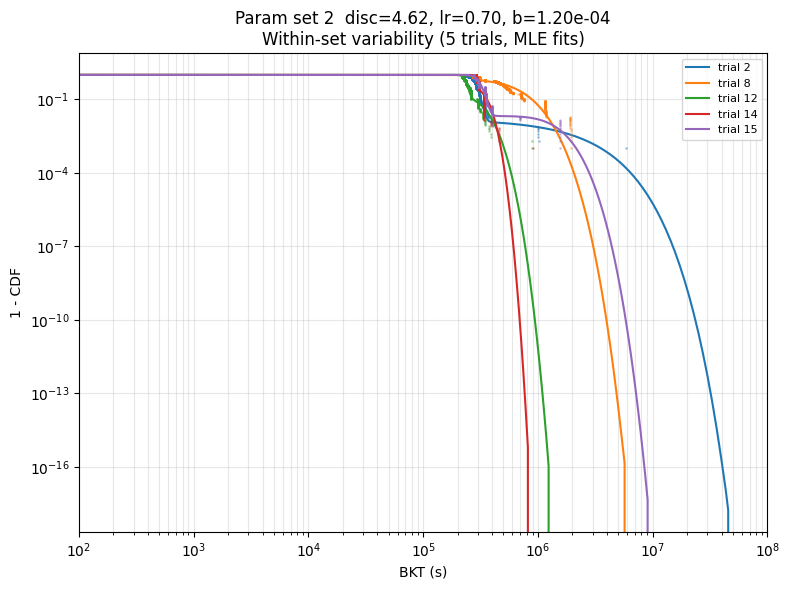

In [46]:
# Within-parameter-set variability: 5 trials overlaid on one plot (MLE fits)
ps_counts = results_df.groupby('paramset_idx').size()
chosen_ps = int(ps_counts[ps_counts >= 5].index[0])
ps_rows   = results_df[results_df['paramset_idx'] == chosen_ps].head(5)
ps_data   = param_sets[chosen_ps - 1]
disc, lr, b = recover_theta(weights[chosen_ps - 1])

colors = list(plt.cm.tab10.colors[:5])
fig, ax = plt.subplots(figsize=(8, 6))
t_grid = np.logspace(np.log10(X_MIN), np.log10(X_MAX), 300)

for color, (_, row) in zip(colors, ps_rows.iterrows()):
    bkt = np.sort(ps_data['trial_data'][int(row['trial_idx']) - 1])
    bkt = bkt[bkt > 0]
    n   = len(bkt)
    ax.loglog(bkt, (n - np.arange(1, n+1)) / n, '.', color=color, ms=2, alpha=0.3)
    s_fit = (row['w1'] * (1 - gamma_dist.cdf(t_grid, a=row['alpha1'], scale=row['beta1'])) +
             (1-row['w1']) * (1 - gamma_dist.cdf(t_grid, a=row['alpha2'], scale=row['beta2'])))
    ax.loglog(t_grid, s_fit, '-', color=color, lw=1.5, label=f"trial {int(row['trial_idx'])}")

ax.set_xlim(X_MIN, X_MAX)
ax.set_ylim(Y_MIN, 1.5)
ax.set_xlabel('BKT (s)'); ax.set_ylabel('1 - CDF')
ax.set_title(f'Param set {chosen_ps}  disc={disc:.2f}, lr={lr:.2f}, b={b:.2e}\n'
             f'Within-set variability (5 trials, MLE fits)')
ax.legend(fontsize=8); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

In [47]:
import time

# Log-log fit loop — same 10 param sets x 20 trials as the MLE loop above
records_ll = []
t_start = time.time()

for ps_idx in range(N_PARAM_SETS):
    ps   = param_sets[ps_idx]
    w    = weights[ps_idx]
    disc, lr, b = recover_theta(w)

    for tr_idx in range(N_TRIALS):
        bkt = ps['trial_data'][tr_idx]
        if len(bkt) == 0:
            continue
        fit = fit_gamma_mixture_loglog(bkt, seed=tr_idx)
        if fit is None:
            continue
        records_ll.append({
            'paramset_idx': ps_idx + 1,
            'discspacing':  disc,
            'length_ratio': lr,
            'b':            b,
            'p0':           ps['p0'],
            'trial_idx':    tr_idx + 1,
            **fit,
        })

    elapsed = time.time() - t_start
    n_done  = sum(1 for r in records_ll if r['paramset_idx'] == ps_idx + 1)
    print(f"Param set {ps_idx+1:3d} done — {n_done} connected trials  [{elapsed:.1f}s elapsed]")

results_loglog_df = pd.DataFrame(records_ll)
print(f"\n{len(results_loglog_df)} fits total in {time.time()-t_start:.1f}s")
results_loglog_df.head()

Param set   1 done — 0 connected trials  [0.0s elapsed]
Param set   2 done — 8 connected trials  [7.8s elapsed]
Param set   3 done — 20 connected trials  [26.1s elapsed]
Param set   4 done — 0 connected trials  [26.1s elapsed]
Param set   5 done — 0 connected trials  [26.1s elapsed]
Param set   6 done — 20 connected trials  [45.1s elapsed]
Param set   7 done — 6 connected trials  [50.5s elapsed]
Param set   8 done — 16 connected trials  [69.7s elapsed]
Param set   9 done — 6 connected trials  [77.9s elapsed]
Param set  10 done — 9 connected trials  [88.2s elapsed]

85 fits total in 88.2s


,paramset_idx,discspacing,length_ratio,b,p0,trial_idx,w1,alpha1,beta1,alpha2,beta2,sse
0,2,4.623168,0.697142,0.00012,0.475,2,0.941527,123.055286,2298.012171,0.208190,3.245118e+06,18.075181
1,2,4.623168,0.697142,0.00012,0.475,8,0.922892,6.731544,64184.522863,10.151790,1.340618e+05,30.808389
2,2,4.623168,0.697142,0.00012,0.475,12,0.858439,156.544849,1525.040054,2.067475,1.254377e+05,59.992066
3,2,4.623168,0.697142,0.00012,0.475,14,0.991003,108.921485,2797.438480,2.884483,2.252562e+05,160.192180
4,2,4.623168,0.697142,0.00012,0.475,15,0.971356,62.137500,4935.856361,2.503690,4.480160e+05,55.491474


In [48]:
results_df.to_csv(outputs_dir / 'gamma_mixture_fits.csv', index=False)
print('Saved gamma_mixture_fits.csv')
results_df.describe()

Saved gamma_mixture_fits.csv


,paramset_idx,discspacing,length_ratio,b,p0,trial_idx,w1,alpha1,beta1,alpha2,beta2,nll
count,85.000000,85.000000,85.000000,85.000000,85.000000,85.000000,8.500000e+01,8.500000e+01,85.000000,8.500000e+01,8.500000e+01,85.000000
mean,6.000000,2.721742,0.579588,0.000219,0.311776,10.741176,7.342743e-01,8.714004e+04,1526.869475,8.186601e+04,1.810905e+05,11117.274737
std,2.618615,1.411434,0.091319,0.000054,0.258236,5.880057,2.413364e-01,5.013416e+05,2080.328962,4.996366e+05,7.516472e+05,837.052247
min,2.000000,1.390162,0.431486,0.000120,0.001000,1.000000,2.061154e-09,1.588716e+01,0.000045,3.246148e-01,5.010848e-02,8075.119743
25%,3.000000,1.507947,0.455608,0.000170,0.175000,6.000000,6.015274e-01,5.498723e+01,184.948088,5.758524e+00,2.088651e+03,10715.171117
50%,6.000000,2.113993,0.600991,0.000245,0.296000,11.000000,8.022817e-01,1.061523e+02,698.301208,1.897991e+01,7.860091e+03,11113.168071
75%,8.000000,4.623168,0.644607,0.000264,0.475000,16.000000,9.107846e-01,6.138800e+02,1999.855434,5.744769e+01,3.266378e+04,11586.320177
max,10.000000,4.859554,0.697142,0.000282,0.770000,20.000000,9.990000e-01,3.269017e+06,11512.614085,3.269017e+06,5.871229e+06,13463.820344


In [49]:
# saves to: outputs/gamma_mixture_fits_loglog.csv
# MLE equivalent: outputs/gamma_mixture_fits.csv
results_loglog_df.to_csv(outputs_dir / 'gamma_mixture_fits_loglog.csv', index=False)
print('Saved gamma_mixture_fits_loglog.csv')
results_loglog_df.describe()

Saved gamma_mixture_fits_loglog.csv


,paramset_idx,discspacing,length_ratio,b,p0,trial_idx,w1,alpha1,beta1,alpha2,beta2,sse
count,85.000000,85.000000,85.000000,85.000000,85.000000,85.000000,8.500000e+01,85.000000,85.000000,85.000000,8.500000e+01,85.000000
mean,6.000000,2.721742,0.579588,0.000219,0.311776,10.741176,8.194647e-01,20548.093649,5496.948983,726.985932,1.259971e+11,48.411057
std,2.618615,1.411434,0.091319,0.000054,0.258236,5.880057,2.006313e-01,121311.219377,13462.471053,5367.882063,1.159083e+12,110.348304
min,2.000000,1.390162,0.431486,0.000120,0.001000,1.000000,2.061154e-09,0.739318,0.001407,0.001420,4.453701e+00,1.154855
25%,3.000000,1.507947,0.455608,0.000170,0.175000,6.000000,7.397493e-01,21.534060,663.559094,1.369976,5.176060e+03,8.626259
50%,6.000000,2.113993,0.600991,0.000245,0.296000,11.000000,8.919089e-01,51.909278,2128.897300,4.382088,3.963537e+04,19.489465
75%,8.000000,4.623168,0.644607,0.000264,0.475000,16.000000,9.525004e-01,103.260457,4789.542444,29.568146,2.252562e+05,50.285718
max,10.000000,4.859554,0.697142,0.000282,0.770000,20.000000,9.999998e-01,925885.645281,102533.313170,49275.200281,1.068647e+13,902.336798


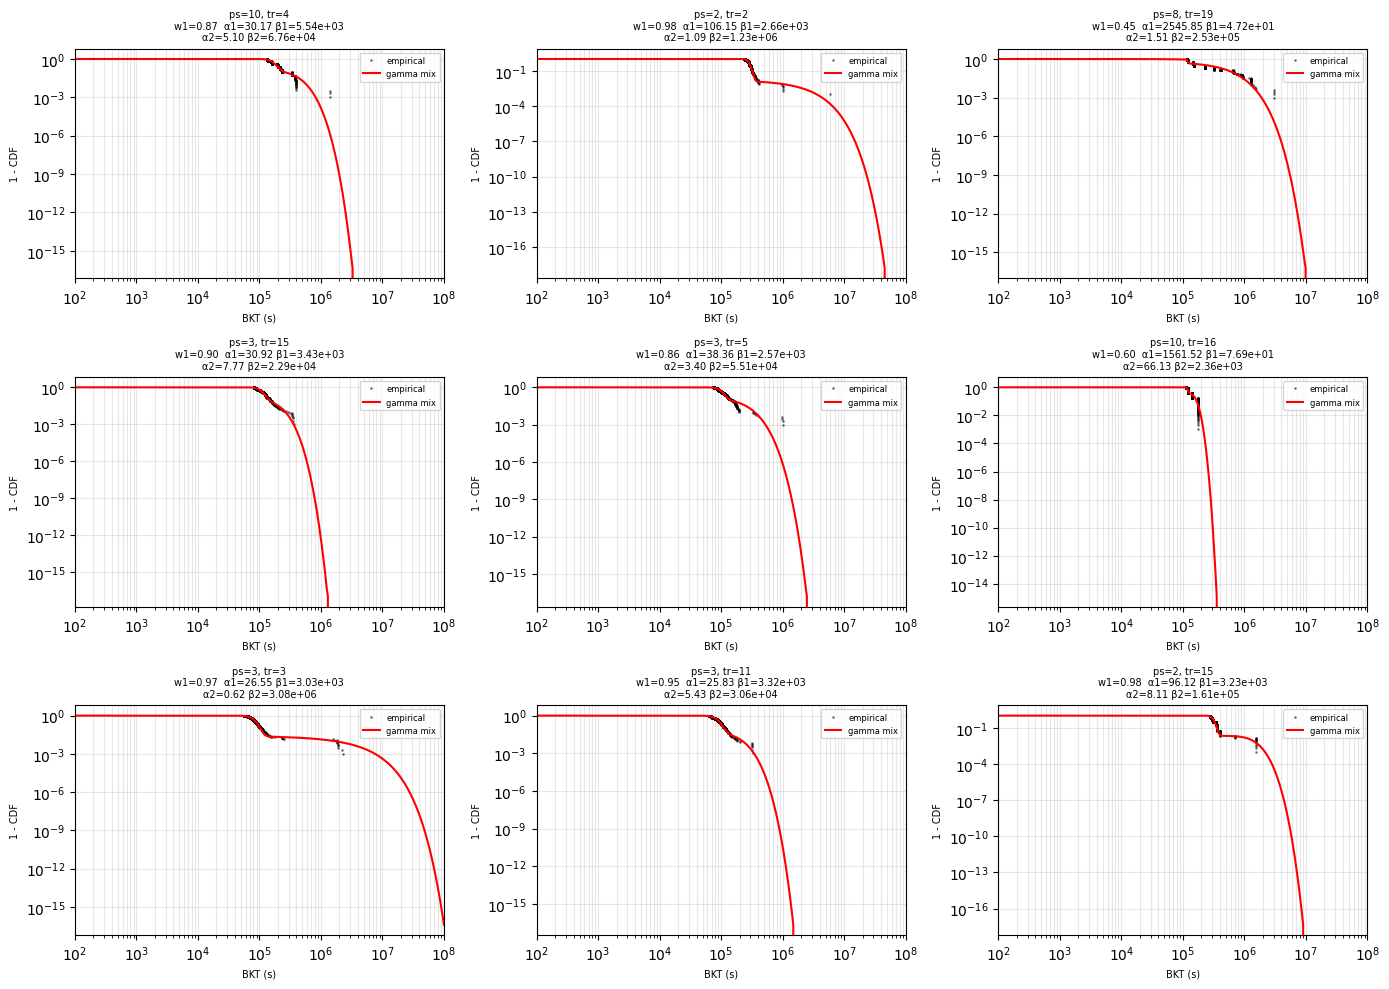

In [50]:
# 3x3 grid of example fits: empirical 1-CDF vs fitted gamma mixture survival curve (MLE)
sample_rows = results_df.sample(min(9, len(results_df)), random_state=42)

t_grid = np.logspace(np.log10(X_MIN), np.log10(X_MAX), 300)

fig, axes = plt.subplots(3, 3, figsize=(14, 10))

for ax, (_, row) in zip(axes.flat, sample_rows.iterrows()):
    ps_idx = int(row['paramset_idx']) - 1
    t_idx  = int(row['trial_idx'])    - 1
    bkt    = param_sets[ps_idx]['trial_data'][t_idx]
    bkt    = np.sort(bkt[np.isfinite(bkt) & (bkt > 0)])

    n        = len(bkt)
    emp_surv = (n - np.arange(1, n + 1)) / n
    ax.loglog(bkt, emp_surv, 'k.', markersize=2, alpha=0.4, label='empirical')

    s_fit  = (row['w1']        * (1 - gamma_dist.cdf(t_grid, a=row['alpha1'], scale=row['beta1'])) +
              (1 - row['w1']) * (1 - gamma_dist.cdf(t_grid, a=row['alpha2'], scale=row['beta2']))  )
    ax.loglog(t_grid, s_fit, 'r-', linewidth=1.5, label='gamma mix')

    ax.set_xlim(X_MIN, X_MAX)
    ax.set_ylim(Y_MIN, 1.5)
    ax.set_title(
        f"ps={int(row['paramset_idx'])}, tr={int(row['trial_idx'])}\n"
        f"w1={row['w1']:.2f}  α1={row['alpha1']:.2f} β1={row['beta1']:.2e}\n"
        f"α2={row['alpha2']:.2f} β2={row['beta2']:.2e}",
        fontsize=7)
    ax.set_xlabel('BKT (s)', fontsize=7)
    ax.set_ylabel('1 - CDF', fontsize=7)
    ax.legend(fontsize=6)
    ax.grid(True, which='both', alpha=0.3)

plt.tight_layout()
plt.show()

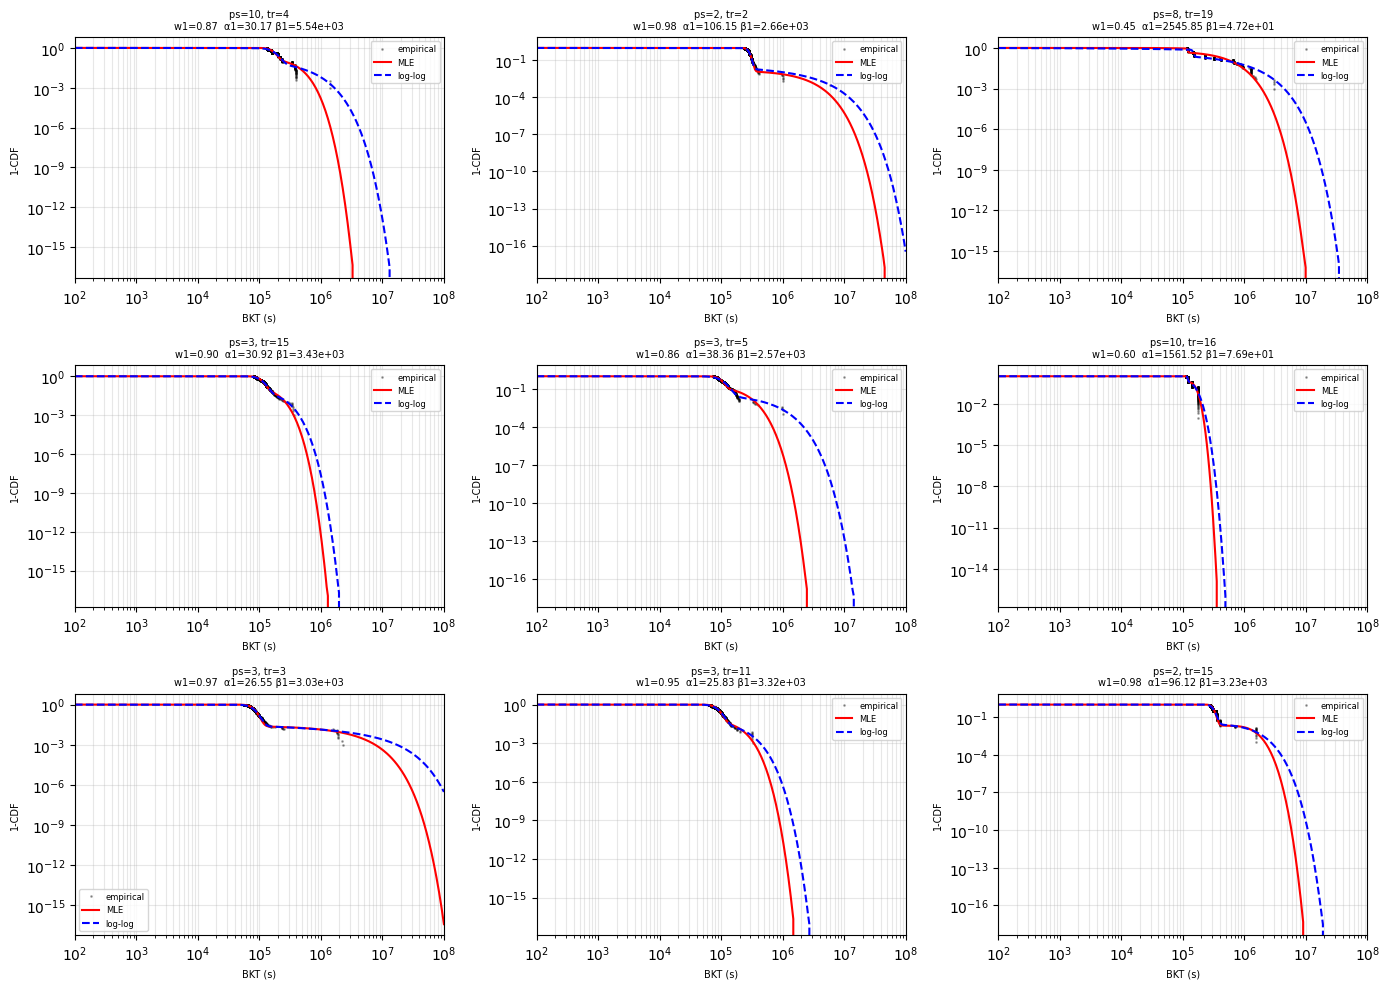

In [51]:
# 3x3 comparison grid: MLE (red) vs log-log (blue dashed) fits on the same 9 trials
# MLE-only grid: cell above
sample_rows = results_df.sample(min(9, len(results_df)), random_state=42)

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
t_grid = np.logspace(np.log10(X_MIN), np.log10(X_MAX), 300)

for ax, (_, row) in zip(axes.flat, sample_rows.iterrows()):
    ps_idx = int(row['paramset_idx']) - 1
    t_idx  = int(row['trial_idx'])    - 1
    bkt    = np.sort(param_sets[ps_idx]['trial_data'][t_idx])
    bkt    = bkt[bkt > 0]
    n      = len(bkt)

    ax.loglog(bkt, (n - np.arange(1, n+1)) / n, 'k.', ms=2, alpha=0.3, label='empirical')

    s_mle = (row['w1'] * (1 - gamma_dist.cdf(t_grid, a=row['alpha1'], scale=row['beta1'])) +
             (1-row['w1']) * (1 - gamma_dist.cdf(t_grid, a=row['alpha2'], scale=row['beta2'])))
    ax.loglog(t_grid, s_mle, 'r-', lw=1.5, label='MLE')

    ll_match = results_loglog_df[
        (results_loglog_df['paramset_idx'] == row['paramset_idx']) &
        (results_loglog_df['trial_idx']    == row['trial_idx'])
    ]
    if len(ll_match):
        r = ll_match.iloc[0]
        s_ll = (r['w1'] * (1 - gamma_dist.cdf(t_grid, a=r['alpha1'], scale=r['beta1'])) +
                (1-r['w1']) * (1 - gamma_dist.cdf(t_grid, a=r['alpha2'], scale=r['beta2'])))
        ax.loglog(t_grid, s_ll, 'b--', lw=1.5, label='log-log')

    ax.set_xlim(X_MIN, X_MAX)
    ax.set_ylim(Y_MIN, 1.5)
    ax.set_title(
        f"ps={int(row['paramset_idx'])}, tr={int(row['trial_idx'])}\n"
        f"w1={row['w1']:.2f}  α1={row['alpha1']:.2f} β1={row['beta1']:.2e}",
        fontsize=7)
    ax.set_xlabel('BKT (s)', fontsize=7); ax.set_ylabel('1-CDF', fontsize=7)
    ax.legend(fontsize=6); ax.grid(True, which='both', alpha=0.3)

plt.tight_layout()
plt.show()

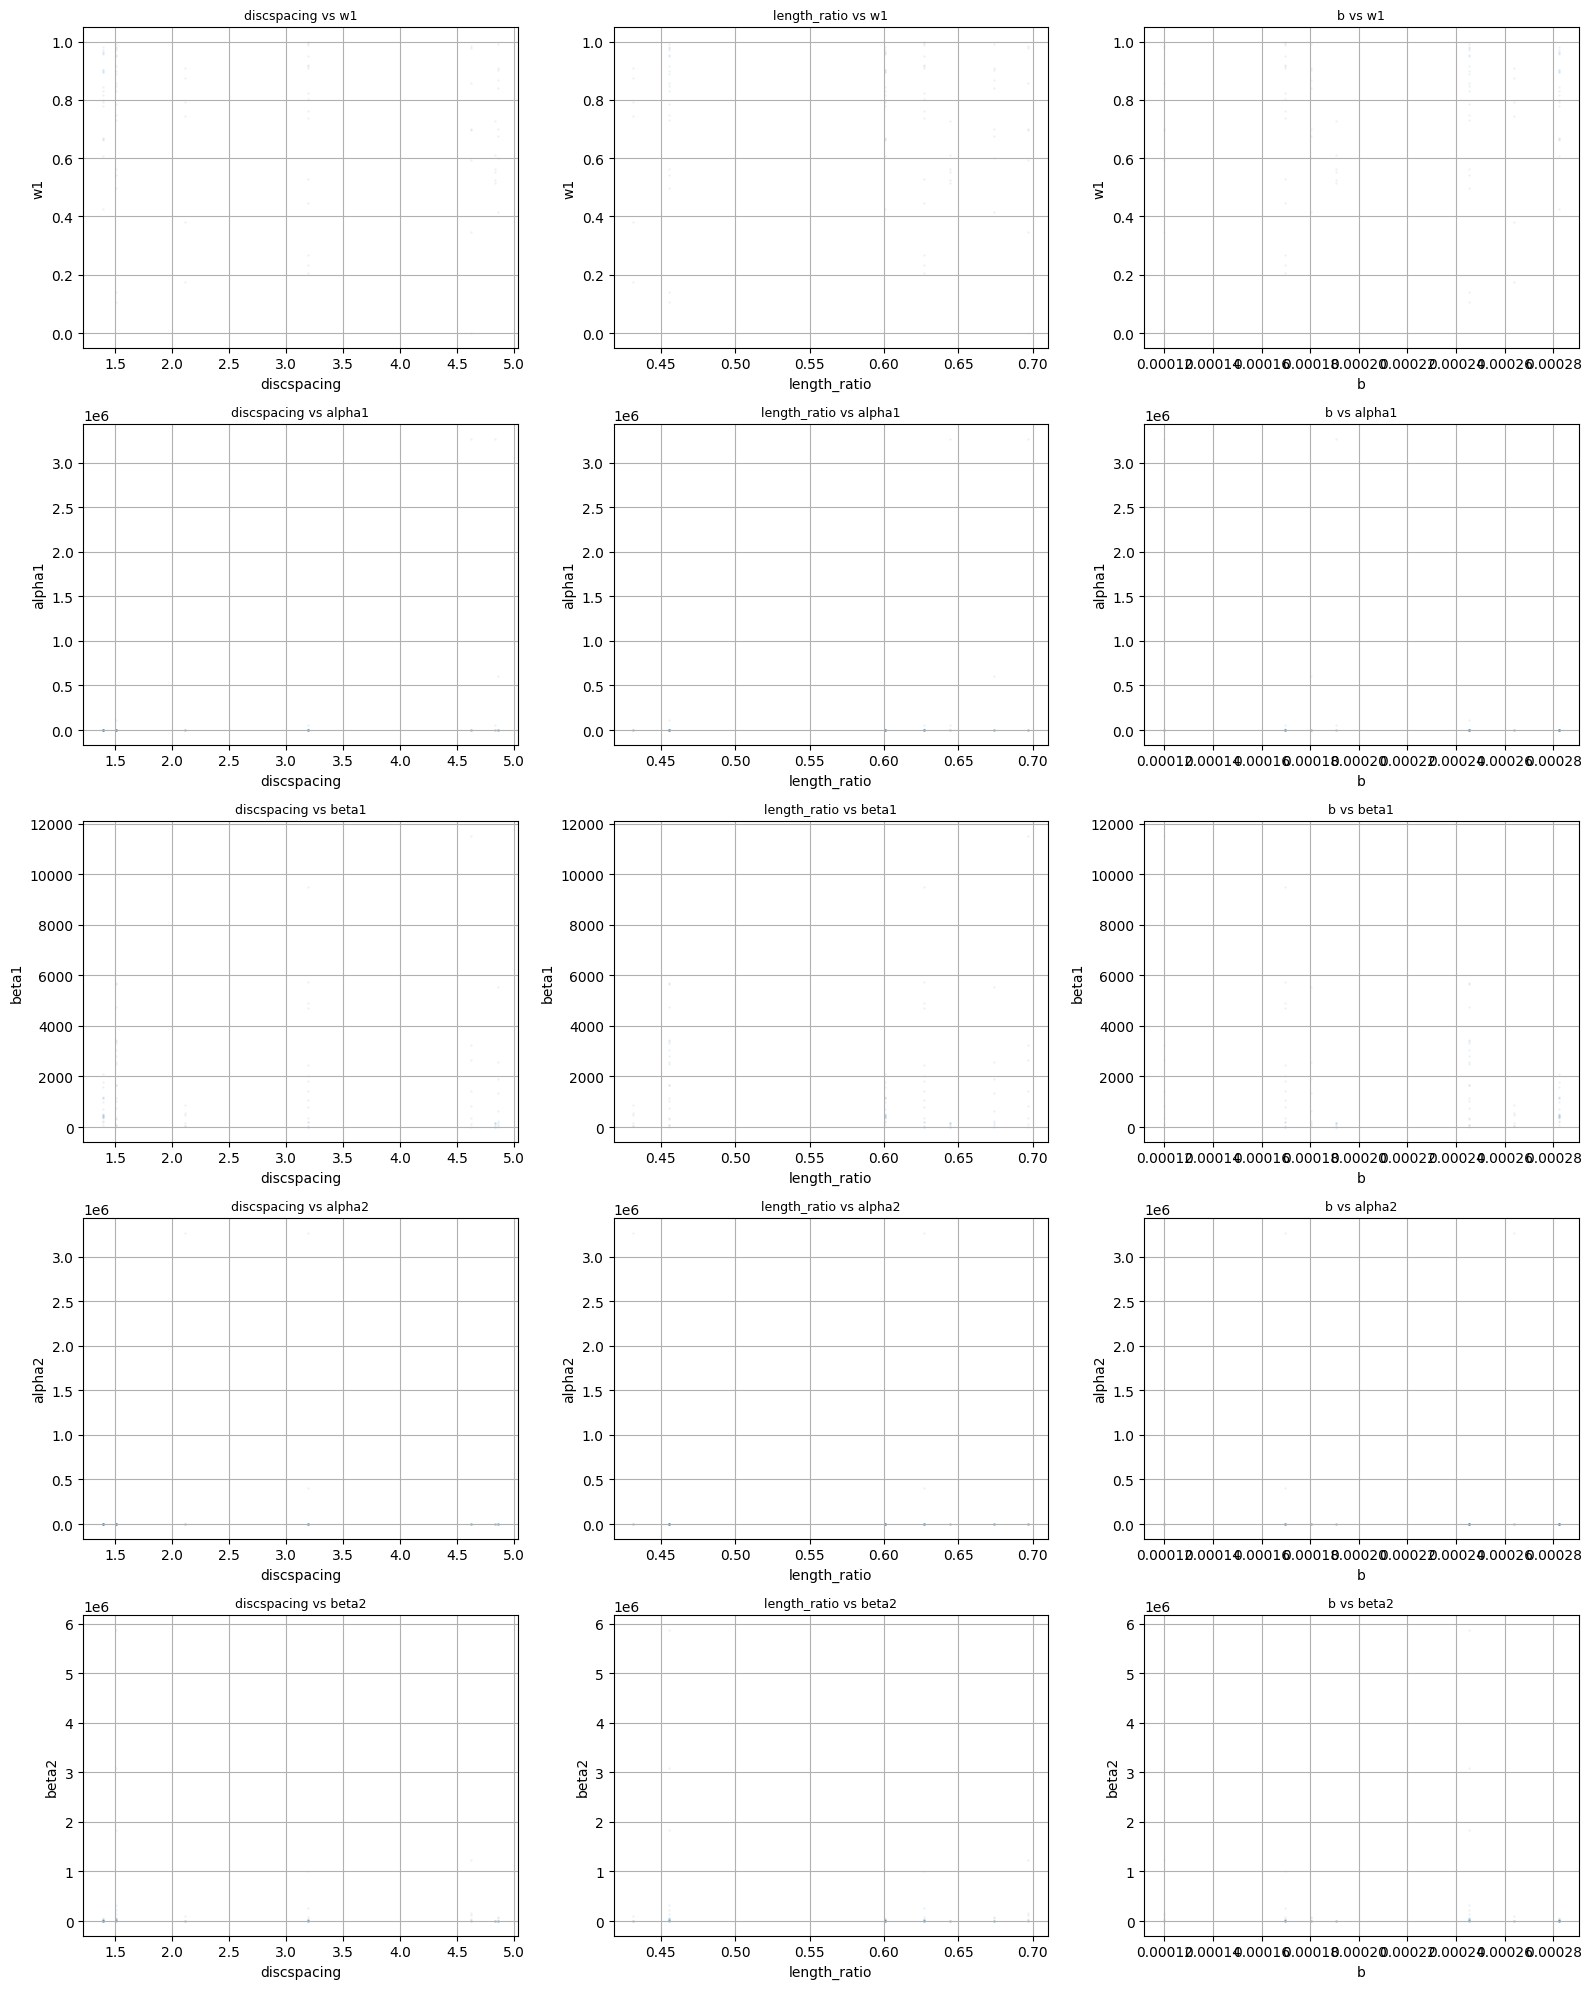

In [52]:
# Scatter plots: each gamma mixture parameter vs each input theta
# Mirrors GMM.ipynb cell-5 (7 outputs x 3 thetas) but here 5 fit params x 3 thetas
fit_param_names   = ['w1', 'alpha1', 'beta1', 'alpha2', 'beta2']
theta_param_names = ['discspacing', 'length_ratio', 'b']

fig, axes = plt.subplots(nrows=5, ncols=3, figsize=(16, 20))

for j, fp in enumerate(fit_param_names):
    for i, tp in enumerate(theta_param_names):
        ax = axes[j, i]
        valid = results_df[fp].notna()
        ax.scatter(results_df.loc[valid, tp], results_df.loc[valid, fp],
                   alpha=0.05, s=1)
        ax.set_xlabel(tp)
        ax.set_ylabel(fp)
        ax.set_title(f'{tp} vs {fp}', fontsize=9)
        ax.grid(True)

plt.tight_layout()
plt.show()